# Coronary Artery Disease Prediction

**Predicting angiographic heart disease from routine clinical measurements: a data audit, honest evaluation and an interpretable model.**

> **Not medical advice.** This is an educational portfolio project built on a research dataset collected in the 1980s. It must not be used to make decisions about anyone's health.

### TL;DR

- The popular Kaggle *"heart attack"* file is the **UCI Cleveland heart disease dataset** with every categorical variable re-coded, the target **inverted**, missing values **hidden behind codes** and one patient **duplicated**. I verified the correct decoding row by row against the original UCI file.
- The target is **coronary artery disease on angiography** (more than 50% narrowing of a major artery), diagnosed at the visit. It is not a heart attack and not a prediction of a future event.
- No patient is deleted as an "outlier". Impossible values are rejected by validation instead, and the data contains none.
- Five models are compared with **nested cross-validation**. Three tie at ROC AUC ≈ 0.91, so the simplest, **logistic regression**, is kept.
- The decision threshold is set to **catch at least 90% of disease cases**. On 61 held-out patients the model reaches **ROC AUC 0.94**, **sensitivity 96%** (27 of 28 cases) and **specificity 70%**.

### Outline

1. Setup
2. The data
3. Data audit: what is wrong with the raw file
4. Cleaning
5. Exploratory analysis
6. Modelling
7. Interpretation
8. Limitations
9. Reproducibility

## 1. Setup

Everything that matters (cleaning, preprocessing, models, evaluation, charts) lives in the tested `heart_disease` package under `src/`. This notebook tells the story and calls it. To run it on Kaggle or Colab, install the package first by uncommenting the line below.

In [1]:
# %pip install -q git+https://github.com/haadijafari/Coronary-Artery-Disease-Prediction.git

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from heart_disease import plots
from heart_disease.config import RAW_DATA_PATH, TARGET_RECALL
from heart_disease.data import clean, load_raw
from heart_disease.evaluation import (
    METRIC_LABELS,
    bootstrap_metrics,
    compare_models,
    out_of_fold_proba,
    select_model,
    summarize_comparison,
)
from heart_disease.interpretation import odds_ratios
from heart_disease.models import candidate_models
from heart_disease.schema import (
    CATEGORICAL_FEATURES,
    CLASS_LABELS,
    FEATURES,
    NUMERIC_FEATURES,
    TARGET,
)
from heart_disease.train import fit_procedure, split

plots.set_theme()
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", None)

# Inside the repository the data sits in data/raw; on Kaggle it is under /kaggle/input.
IN_REPOSITORY = RAW_DATA_PATH.exists()
DATA_PATH = RAW_DATA_PATH if IN_REPOSITORY else next(Path("/kaggle/input").rglob("heart.csv"))


def show(fig, name):
    # Figures are also written to reports/figures for the README when run inside the repository.
    if IN_REPOSITORY:
        plots.save_figure(fig, name)
    display(fig)
    plt.close(fig)

## 2. The data

The file is the **Cleveland** subset of the [UCI Heart Disease dataset](https://archive.ics.uci.edu/dataset/45/heart+disease) (Detrano et al., 1989): patients referred to the Cleveland Clinic for **coronary angiography** in 1981–1984, described by 13 of the 76 attributes originally recorded. It circulates on Kaggle as the *"Heart Attack Analysis & Prediction Dataset"*.

**What the target really is.** Every patient underwent angiography, and the original label is the number of major coronary arteries with more than 50% diameter narrowing. The binary target used here means **"coronary artery disease present"**: at least one such artery. The label is a diagnosis made at the time of the visit, so this is a *diagnostic* model, not a forecast of heart attacks.

In [3]:
raw = load_raw(DATA_PATH)
print(f"{raw.shape[0]} rows × {raw.shape[1]} columns")
raw.head()

303 rows × 14 columns


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


The column names are cryptic, so here is the data dictionary used throughout the project. It is generated from `heart_disease.schema`, the single place where names, meanings, units and code mappings are defined.

In [4]:
pd.DataFrame(
    {
        "column": f.name,
        "raw name": f.raw_name,
        "meaning": f.label,
        "unit / categories": f.unit or ", ".join(f.categories) or "count",
    }
    for f in FEATURES
).set_index("column")

,raw name,meaning,unit / categories
column,,,
age,age,Age,years
sex,sex,Sex,"Female, Male"
chest_pain,cp,Chest pain type,"Typical angina, Atypical angina, Non-anginal pain, Asymptomatic"
resting_bp,trtbps,Resting blood pressure,mm Hg
cholesterol,chol,Serum cholesterol,mg/dl
high_fasting_sugar,fbs,Fasting blood sugar > 120 mg/dl,"No, Yes"
rest_ecg,restecg,Resting ECG,"Normal, ST-T abnormality, LV hypertrophy"
max_heart_rate,thalachh,Maximum heart rate,bpm
exercise_angina,exng,Exercise-induced angina,"No, Yes"


## 3. Data audit: what is wrong with the raw file

`raw.info()` reports 303 complete rows of integers, which looks clean. It is not. Four problems hide in this file, and each one has misled many published notebooks.

### 3.1 The categorical codes were remapped

The UCI documentation codes chest pain as 1 = typical angina … 4 = asymptomatic, and many Kaggle notebooks apply that description to this file. But the Kaggle file uses **0–3 in a different order**. Matching the number of patients and the disease rate of every code against the original UCI file reveals the true mapping. The reference columns below were computed from UCI's `processed.cleveland.data`. They differ from this file by at most one patient because of the duplicate described in 3.4. After decoding, each of the 302 unique rows matches a UCI patient exactly.

In [5]:
# Patients and disease rate per category in the original UCI file (processed.cleveland.data).
UCI_REFERENCE = {
    "cp": {
        "Typical angina": (23, 0.30),
        "Atypical angina": (50, 0.18),
        "Non-anginal pain": (86, 0.21),
        "Asymptomatic": (144, 0.73),
    },
    "restecg": {
        "Normal": (151, 0.37),
        "ST-T abnormality": (4, 0.75),
        "LV hypertrophy": (148, 0.54),
    },
    "slp": {"Upsloping": (142, 0.25), "Flat": (140, 0.65), "Downsloping": (21, 0.57)},
    "thall": {"Normal": (166, 0.22), "Fixed defect": (18, 0.67), "Reversible defect": (117, 0.76)},
}

rows = []
for feature in FEATURES:
    if feature.raw_name not in UCI_REFERENCE:
        continue
    for code, label in feature.codes.items():
        in_file = raw[raw[feature.raw_name] == code]
        uci_n, uci_rate = UCI_REFERENCE[feature.raw_name][label]
        rows.append(
            {
                "column": feature.raw_name,
                "Kaggle code": code,
                "decoded as": label,
                "Kaggle n": len(in_file),
                "UCI n": uci_n,
                "Kaggle disease rate": 1 - in_file["output"].mean(),
                "UCI disease rate": uci_rate,
            }
        )
pd.DataFrame(rows).set_index(["column", "Kaggle code"])

decoded as  Kaggle n  UCI n  Kaggle disease rate  \
column  Kaggle code                                                            
cp      3               Typical angina        23     23                0.304   
        1              Atypical angina        50     50                0.180   
        2             Non-anginal pain        87     86                0.207   
        0                 Asymptomatic       143    144                0.727   
restecg 1                       Normal       152    151                0.368   
        2             ST-T abnormality         4      4                0.750   
        0               LV hypertrophy       147    148                0.537   
slp     2                    Upsloping       142    142                0.246   
        1                         Flat       140    140                0.650   
        0                  Downsloping        21     21                0.571   
thall   2                       Normal       166    166                0.217   
        1                 Fixed defect        18     18                0.667   
        3            Reversible defect       117    117                0.761   

                     UCI disease rate  
column  Kaggle code                    
cp      3                        0.30  
        1                        0.18  
        2                        0.21  
        0                        0.73  
restecg 1                        0.37  
        2                        0.75  
        0                        0.54  
slp     2                        0.25  
        1                        0.65  
        0                        0.57  
thall   2                        0.22  
        1                        0.67  
        3                        0.76

Both columns agree code by code, so the mapping is unambiguous. In particular, **code 0 of `cp` is *asymptomatic***, the chest-pain type most associated with disease, not "typical angina" as the UCI documentation would suggest.

### 3.2 The target is inverted

In UCI, 164 of the 303 patients have no disease. In this file, 165 rows have `output = 1`, so **`output = 1` means *no* disease**. That is the opposite of what the Kaggle data card states. The clinical picture confirms it: the `output = 1` group is younger, reaches higher peak heart rates, rarely has exercise-induced angina and has fewer narrowed vessels.

In [6]:
raw.groupby("output")[["age", "thalachh", "exng", "oldpeak", "caa"]].mean().rename(
    index={0: "output = 0", 1: "output = 1"}
)

,age,thalachh,exng,oldpeak,caa
output,,,,,
output = 0,56.601,139.101,0.551,1.586,1.167
output = 1,52.497,158.467,0.139,0.583,0.364


The cleaned data uses `has_disease = 1 - output`, so that **disease is the positive class** and "sensitivity" means what a clinician expects.

### 3.3 Missing values hide behind out-of-range codes

`isna()` finds nothing, but two codes fall outside the documented ranges. `caa` (vessels coloured by fluoroscopy) is documented as 0–3, yet five rows hold `4`. `thall` (thallium test) has three documented results, yet two rows hold `0`. These are exactly the rows that are missing in the UCI file.

In [7]:
print("Explicit missing values:", int(raw.isna().sum().sum()))
print("caa  value counts:", raw["caa"].value_counts().sort_index().to_dict())
print("thall value counts:", raw["thall"].value_counts().sort_index().to_dict())

Explicit missing values: 0
caa  value counts: {0: 175, 1: 65, 2: 38, 3: 20, 4: 5}
thall value counts: {0: 2, 1: 18, 2: 166, 3: 117}


### 3.4 One patient appears twice

Rows 163 and 164 are identical across all 14 columns, including the continuous measurements. Comparing against UCI shows that the last UCI patient was duplicated and one other patient (UCI row 185) is absent. A duplicate can land in both the training and test sets and inflate the evaluation, so it is removed.

In [8]:
raw[raw.duplicated(keep=False)]

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


### 3.5 Unusual values are not errors

A common reflex is to delete everything outside 1.5 × IQR. On clinical data that is a mistake. Resting blood pressure of 200 mm Hg and cholesterol of 564 mg/dl are high but entirely plausible, and high blood pressure is a risk factor in itself. A deployed model also cannot refuse to score a patient because their numbers are unusual.

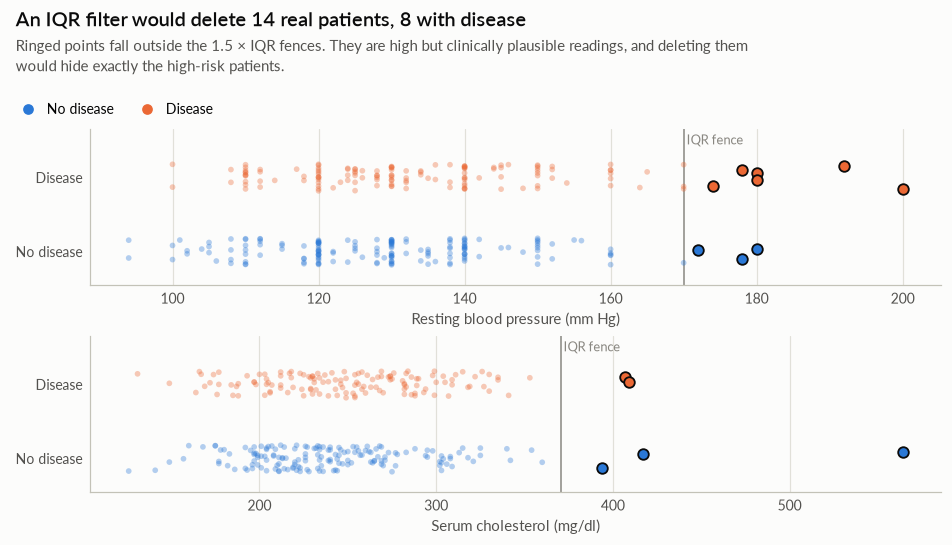

In [9]:
show(plots.plot_iqr_audit(clean(raw), ["resting_bp", "cholesterol"]), "iqr_audit")

Instead of a statistical filter, the cleaning step applies **physiological plausibility ranges** and **fails loudly** if any value is impossible, such as a cholesterol of 0. This file passes every check.

In [10]:
pd.DataFrame(
    {
        "column": f.name,
        "plausible range": f"{f.valid_range[0]}–{f.valid_range[1]}",
        "observed range": f"{raw[f.raw_name][~raw[f.raw_name].isin(f.missing_codes)].min()}–"
        f"{raw[f.raw_name][~raw[f.raw_name].isin(f.missing_codes)].max()}",
    }
    for f in FEATURES
    if f.valid_range
).set_index("column")

,plausible range,observed range
column,,
age,18–100,29–77
resting_bp,70–250,94–200
cholesterol,100–700,126–564
max_heart_rate,60–220,71–202
st_depression,0–7,0.0–6.2
major_vessels,0–3,0–3


## 4. Cleaning

`heart_disease.data.clean` fixes exactly the four problems above and nothing else. It decodes the categories, exposes the hidden missing values, drops the duplicate and inverts the target. It also validates the schema before touching the data. Each behaviour is covered by a unit test in `tests/test_data.py`.

In [11]:
df = clean(raw)
print(f"{len(df)} patients after removing the duplicate")
print("Missing values:", df.isna().sum()[lambda s: s > 0].to_dict())
df.head()

302 patients after removing the duplicate
Missing values: {'major_vessels': 4, 'thal': 2}


,age,sex,chest_pain,resting_bp,cholesterol,high_fasting_sugar,rest_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,major_vessels,thal,has_disease
0,63,Male,Typical angina,145,233,Yes,LV hypertrophy,150,No,2.3,Downsloping,0.0,Fixed defect,0
1,37,Male,Non-anginal pain,130,250,No,Normal,187,No,3.5,Downsloping,0.0,Normal,0
2,41,Female,Atypical angina,130,204,No,LV hypertrophy,172,No,1.4,Upsloping,0.0,Normal,0
3,56,Male,Atypical angina,120,236,No,Normal,178,No,0.8,Upsloping,0.0,Normal,0
4,57,Female,Asymptomatic,120,354,No,Normal,163,Yes,0.6,Upsloping,0.0,Normal,0


The seven missing values are **not imputed here**. Imputation learns from data (a median, a most frequent category), so it lives inside the model pipeline. There it is refit on the training folds only and cannot leak information from the rows used for evaluation.

## 5. Exploratory analysis

In [12]:
counts = df[TARGET].value_counts().rename(CLASS_LABELS)
print(counts.to_string())
print(f"Disease prevalence: {df[TARGET].mean():.1%}")

has_disease
No disease    164
Disease       138
Disease prevalence: 45.7%


**The classes are close to balanced** (46% disease), so a model that always predicts "no disease" would be only 54% accurate. Accuracy alone is still not the right yardstick, because the two errors have different costs: a missed case is far worse than a false alarm. Section 6.3 handles that asymmetry explicitly.

Note also that 46% is the prevalence among patients **referred for angiography**, not in the general population. Any probability this model outputs applies to patients like these and would need recalibration elsewhere.

### 5.1 Numeric measurements

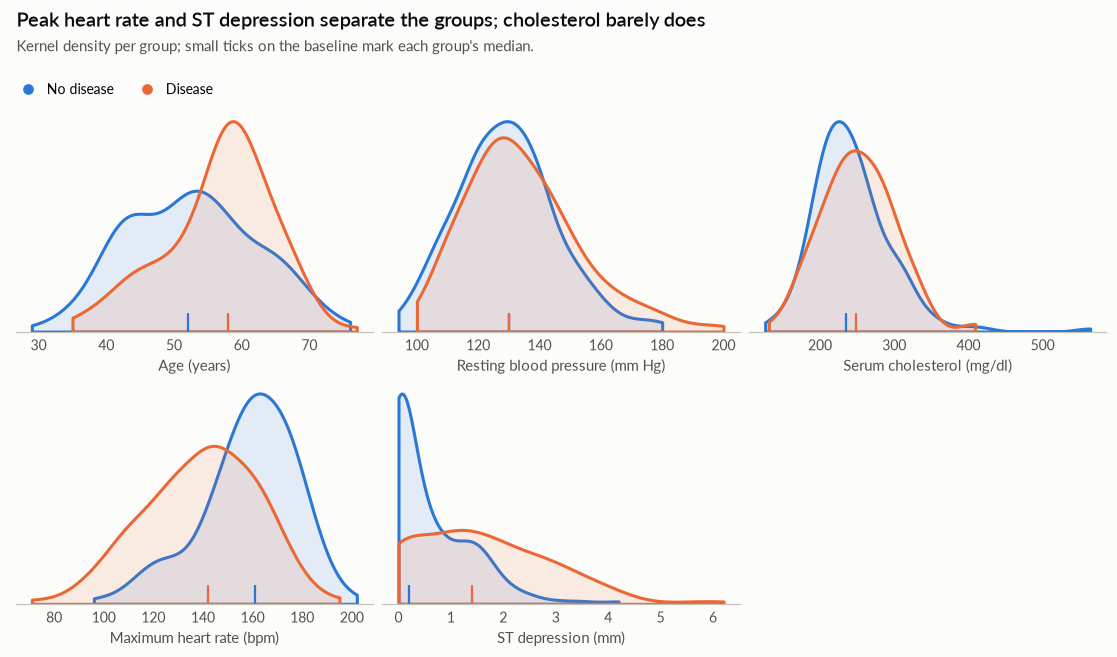

In [13]:
show(
    plots.plot_numeric_distributions(
        df,
        ["age", "resting_bp", "cholesterol", "max_heart_rate", "st_depression"],
        title="Peak heart rate and ST depression separate the groups; cholesterol barely does",
    ),
    "numeric_distributions",
)

### 5.2 Categorical findings

For categorical variables, the most readable view is the disease rate within each category. With roughly 300 patients some groups are tiny, so every rate carries a 95% Wilson interval.

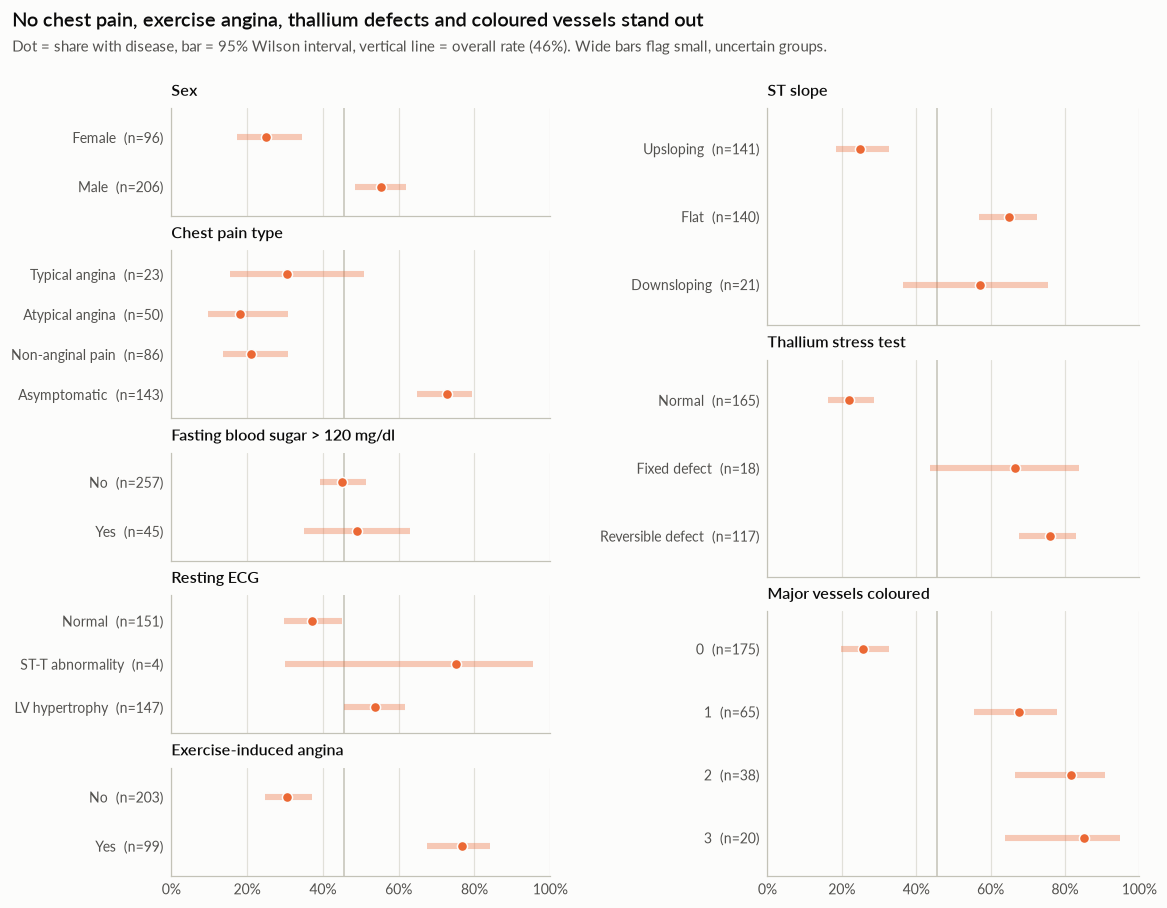

In [14]:
show(
    plots.plot_disease_rates(
        df,
        [*CATEGORICAL_FEATURES, "major_vessels"],
        title="No chest pain, exercise angina, thallium defects and coloured vessels stand out",
    ),
    "disease_rates",
)

A few things stand out:

- **Asymptomatic patients have the highest disease rate (73%)**. This sounds paradoxical but is well known in this cohort: patients without typical symptoms were referred because other tests looked abnormal.
- **Exercise-induced angina, a flat ST slope, a reversible thallium defect and any coloured vessel** each push the rate well above the 46% average.
- **Fasting blood sugar shows no relationship**, and the **ST-T abnormality** group has only four patients, so its interval spans almost everything.
- **Men have more than twice the disease rate of women** in this sample (55% vs 25%).

### 5.3 Relationships between measurements

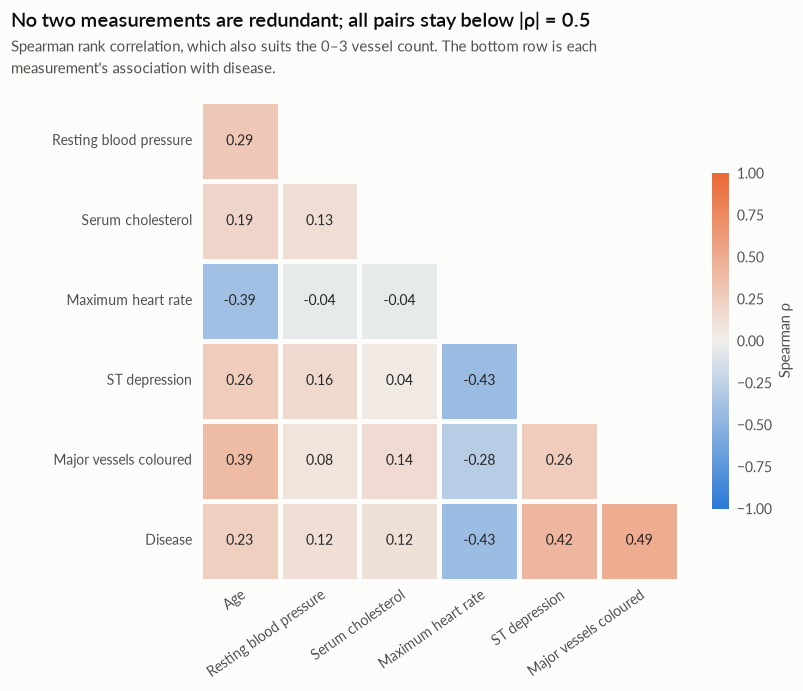

In [15]:
show(
    plots.plot_correlation(
        df,
        NUMERIC_FEATURES,
        title="No two measurements are redundant; all pairs stay below |ρ| = 0.5",
    ),
    "correlation",
)

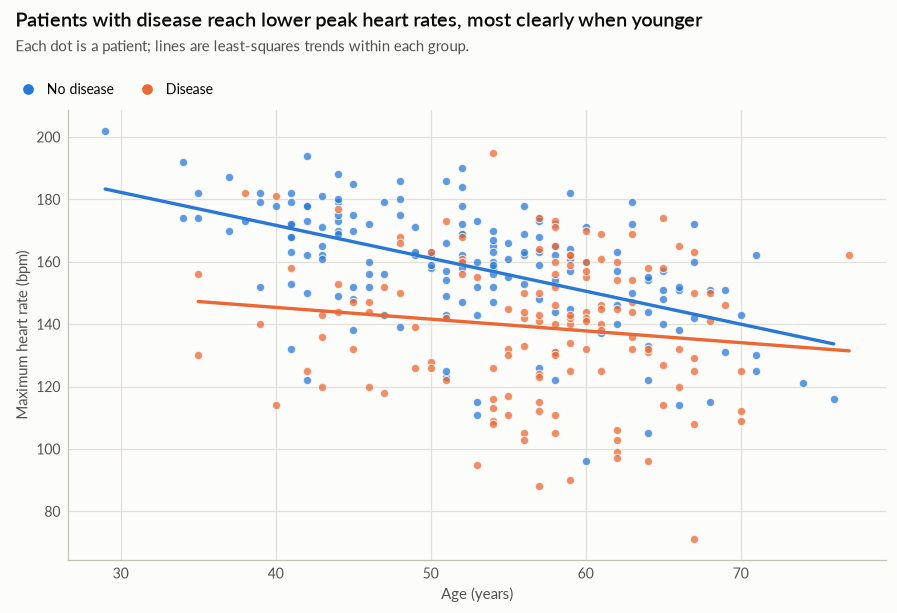

In [16]:
show(
    plots.plot_age_vs_heart_rate(
        df, title="Patients with disease reach lower peak heart rates, most clearly when younger"
    ),
    "age_vs_heart_rate",
)

Peak heart rate falls with age for everyone, and patients with disease sit consistently lower. The gap is widest among younger patients, which is why the model needs both variables rather than either alone. No pair of measurements is strongly collinear, so a linear model's coefficients stay stable.

## 6. Modelling

### 6.1 Protocol

The goal is an **honest estimate** of how the model would do on new patients, so every decision is made without looking at the test set:

1. **Hold out 20%** of patients (stratified by diagnosis) as a test set and do not touch them until step 6.
2. **Preprocessing lives inside the pipeline**: median / most-frequent imputation, standard scaling, and one-hot encoding with the clinically normal category as reference. It is refit on every training fold.
3. **Compare five candidates with nested cross-validation**: 5 × 5 repeated stratified outer folds estimate performance, while an inner 5-fold grid search tunes hyperparameters on ROC AUC within each outer training fold.
4. **Pick the simplest model within one standard error** of the best mean ROC AUC. With 241 training patients, small differences are noise and simplicity is the better bet.
5. **Choose the decision threshold** from out-of-fold predictions on the training set, as the highest threshold that still catches **90% of disease cases**.
6. **Score the chosen model once** on the test set, with bootstrap confidence intervals.

In [17]:
X_train, X_test, y_train, y_test = split(df)
print(f"Training: {len(X_train)} patients ({y_train.mean():.0%} disease)")
print(f"Test:     {len(X_test)} patients ({y_test.mean():.0%} disease)")

candidates = candidate_models()


def describe_grid(grid):
    parts = []
    for key, values in grid.items():
        shown = ", ".join(f"{v:g}" if isinstance(v, float) else str(v) for v in values)
        parts.append(f"{key.split('__')[-1]} ∈ {{{shown}}}")
    return "; ".join(parts) or "none"


pd.DataFrame(
    {
        "model": c.name,
        "hyperparameter grid": describe_grid(c.param_grid),
        "complexity rank": c.complexity,
    }
    for c in candidates
).set_index("model")

Training: 241 patients (46% disease)
Test:     61 patients (46% disease)


,hyperparameter grid,complexity rank
model,,
Baseline,none,0
Logistic regression,"C ∈ {0.001, 0.00316228, 0.01, 0.0316228, 0.1, 0.316228, 1, 3.16228, 10, 31.6228, 100}",1
SVM (RBF kernel),"C ∈ {0.1, 1, 10}; gamma ∈ {scale, 0.01}",2
Random forest,"min_samples_leaf ∈ {1, 5, 10}; max_features ∈ {sqrt, 0.5}",3
Gradient boosting,"learning_rate ∈ {0.03, 0.1}; max_depth ∈ {2, 3}",4


### 6.2 Model comparison

This is the expensive step: 25 outer folds × every grid point × 5 inner folds. It takes a few minutes on a laptop.

In [18]:
scores = compare_models(candidates, X_train, y_train, n_splits=5, n_repeats=5)
summary = summarize_comparison(scores, candidates)
selected_name = select_model(summary)
chosen = next(c for c in candidates if c.name == selected_name)

(
    scores.pivot_table(index="model", columns="metric", values="value", aggfunc="mean")
    .rename(columns=METRIC_LABELS)
    .loc[summary["model"]]
)

metric,Average precision,Balanced accuracy,Brier score,ROC AUC,Sensitivity (recall),Specificity
model,,,,,,
SVM (RBF kernel),0.910,0.845,0.117,0.910,0.800,0.890
Logistic regression,0.907,0.842,0.120,0.909,0.785,0.898
Random forest,0.910,0.834,0.129,0.908,0.789,0.879
Gradient boosting,0.906,0.827,0.123,0.903,0.800,0.855
Baseline,0.456,0.500,0.248,0.500,0.000,1.000


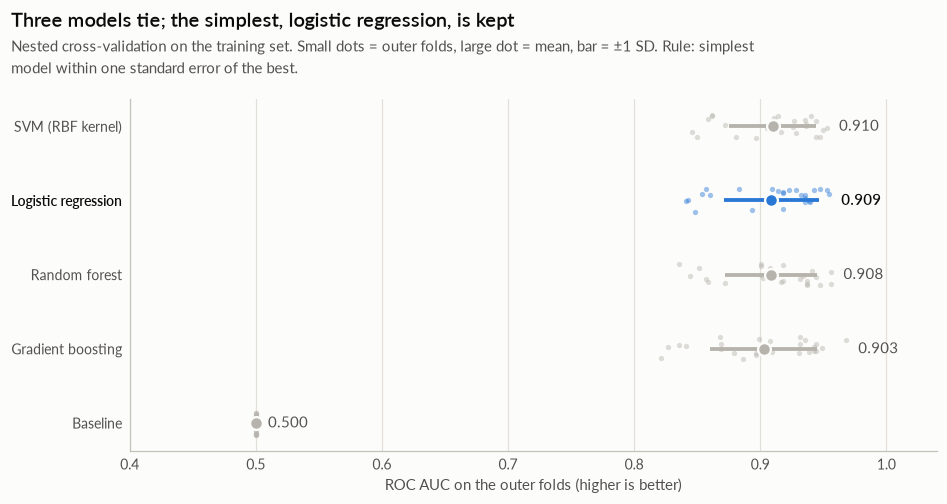

In [19]:
show(plots.plot_model_comparison(scores, selected_name), "model_comparison")

The SVM, logistic regression and random forest are statistically indistinguishable (differences of 0.002 in mean AUC against a fold-to-fold spread of about 0.035). Gradient boosting is slightly behind, which is typical on a dataset this small. The one-standard-error rule therefore picks **logistic regression**. It is simpler, better calibrated than the tree models (lower Brier score), and every prediction it makes can be explained exactly.

### 6.3 Tuning and choosing the threshold

The default 0.5 threshold treats a missed disease case and a false alarm as equally bad. For a diagnostic aid they are not, so the threshold is chosen to **catch at least 90% of disease cases**. The choice uses out-of-fold predictions on the training set only, so the test set stays untouched.

Selected hyperparameters: {'C': 0.1}
Decision threshold:       0.308


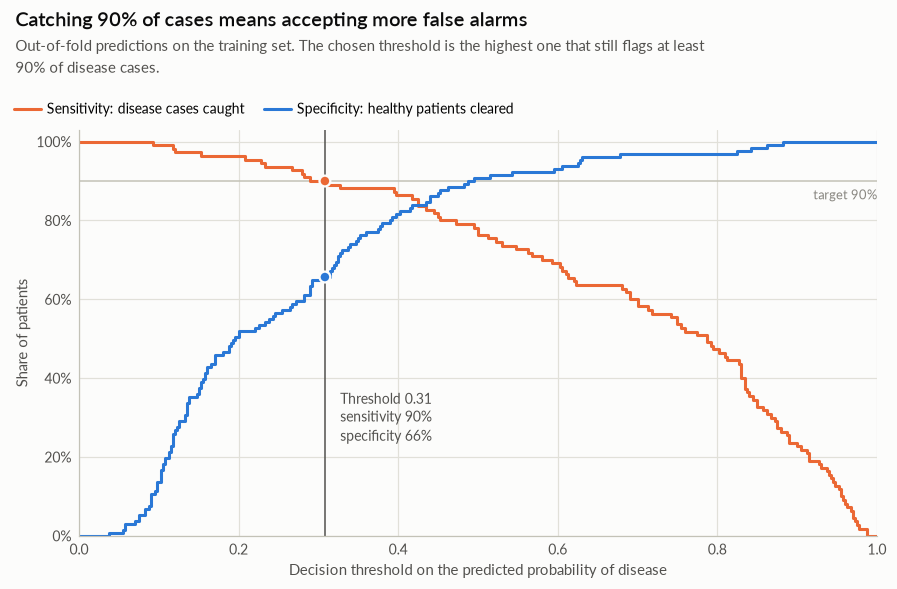

In [20]:
evaluated = fit_procedure(chosen, X_train, y_train)
print(f"Selected hyperparameters: {evaluated.params}")
print(f"Decision threshold:       {evaluated.threshold:.3f}")

oof_proba = out_of_fold_proba(evaluated.pipeline, X_train, y_train)
show(
    plots.plot_threshold_tradeoff(y_train, oof_proba, evaluated.threshold, TARGET_RECALL),
    "threshold_tradeoff",
)

### 6.4 Evaluation on the held-out test set

This is the first and only time the test set is used.

In [21]:
test_proba = evaluated.predict_proba(X_test)


def metric_table(threshold):
    table = bootstrap_metrics(y_test, test_proba, threshold).set_index("metric")
    table.index = table.index.map(METRIC_LABELS)
    return table.apply(
        lambda r: f"{r['estimate']:.3f}  [{r['lower']:.3f}, {r['upper']:.3f}]", axis=1
    )


pd.DataFrame(
    {
        f"chosen threshold ({evaluated.threshold:.2f})": metric_table(evaluated.threshold),
        "default threshold (0.50)": metric_table(0.5),
    }
).rename_axis("metric  ·  estimate [95% bootstrap CI]")

,chosen threshold (0.31),default threshold (0.50)
metric · estimate [95% bootstrap CI],,
ROC AUC,"0.936 [0.872, 0.985]","0.936 [0.872, 0.985]"
Average precision,"0.919 [0.837, 0.984]","0.919 [0.837, 0.984]"
Brier score,"0.110 [0.075, 0.149]","0.110 [0.075, 0.149]"
Sensitivity (recall),"0.964 [0.893, 1.000]","0.786 [0.643, 0.929]"
Specificity,"0.697 [0.545, 0.848]","0.879 [0.758, 0.970]"
Precision (PPV),"0.730 [0.636, 0.848]","0.846 [0.731, 0.960]"
Negative predictive value,"0.958 [0.870, 1.000]","0.829 [0.732, 0.938]"
Accuracy,"0.820 [0.721, 0.902]","0.836 [0.738, 0.918]"
Balanced accuracy,"0.831 [0.742, 0.909]","0.832 [0.739, 0.919]"


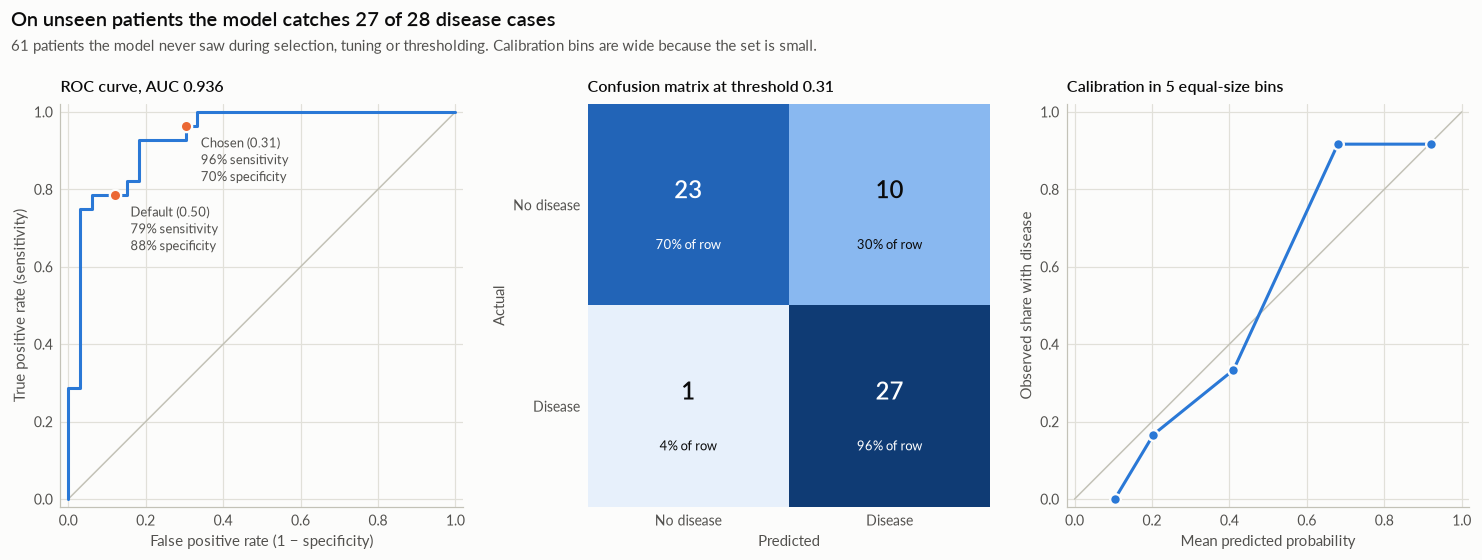

In [22]:
show(plots.plot_test_performance(y_test, test_proba, evaluated.threshold), "test_performance")

- **Discrimination is strong**: ROC AUC 0.94 on unseen patients, in line with the cross-validated 0.91. The test set is small, and the interval runs from about 0.87 to 0.98.
- **The threshold does its job**: 27 of the 28 disease cases are flagged (sensitivity 96%). The price is 10 false alarms among 33 healthy patients (specificity 70%). At the default 0.5, the model would have missed 6 cases instead of 1.
- **A negative prediction is reassuring**: 23 of the 24 patients the model clears are truly disease-free (NPV 0.96).
- **Calibration is reasonable** for a set of 61. With only about 12 patients per bin, the curve is noisy, and the Brier score of 0.11 is well below the 0.25 of an uninformative model.

## 7. Interpretation

### 7.1 What the model has learned

Logistic regression coefficients become **odds ratios**. Numeric terms are per one standard deviation; categorical terms are relative to the reference category. The intervals come from refitting the tuned pipeline on 1,000 bootstrap resamples of the training set.

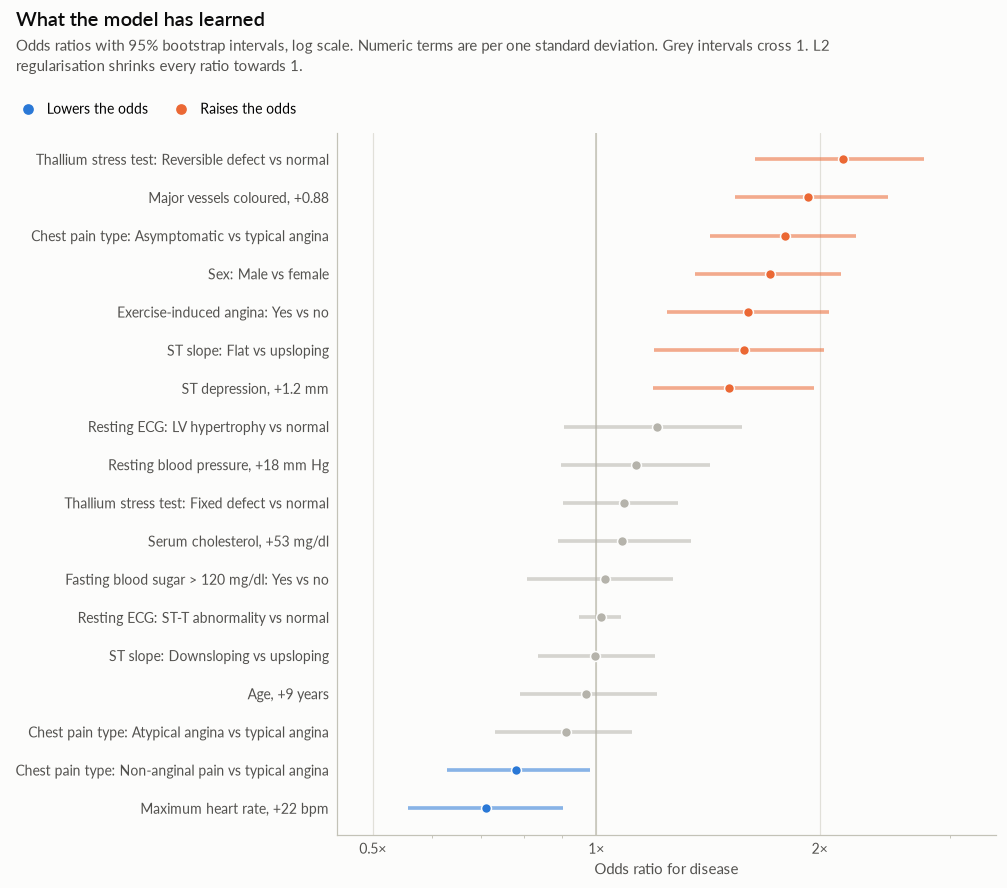

In [23]:
or_table = odds_ratios(evaluated.pipeline, X_train, y_train, n_resamples=1_000)
scales = X_train[NUMERIC_FEATURES].std().to_dict()
show(plots.plot_odds_ratios(or_table, scales), "odds_ratios")

The strongest effects match clinical knowledge: a **reversible thallium defect** (ischaemia under stress), **more vessels coloured on fluoroscopy**, **an asymptomatic presentation**, **male sex**, **exercise-induced angina**, a **flat ST slope** and **more ST depression** raise the odds. A **higher peak heart rate** lowers them. Cholesterol, resting blood pressure, fasting blood sugar and age add little once the other measurements are known.

Two caveats: these are **associations in a referral cohort, not causal effects**, and L2 regularisation deliberately **shrinks every ratio towards 1** in exchange for better predictions.

### 7.2 One patient, explained

Because the model is linear, each prediction splits exactly into one contribution per feature, measured relative to an average patient. The most instructive case is the one the model got wrong, so here is the single disease case it missed in the test set.

,missed patient
age,57
sex,Male
chest_pain,Atypical angina
resting_bp,154
cholesterol,232
high_fasting_sugar,No
rest_ecg,LV hypertrophy
max_heart_rate,164
exercise_angina,No
st_depression,0.0


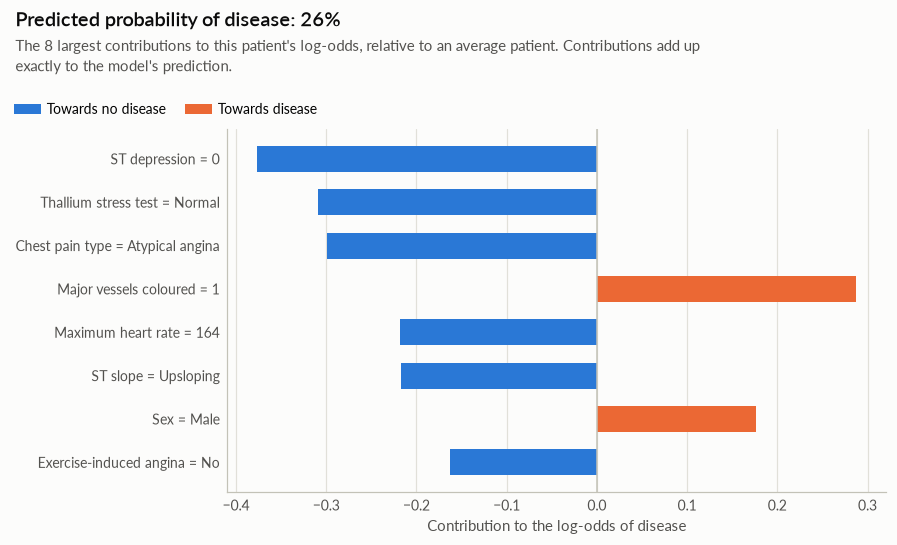

In [24]:
missed = X_test[(y_test == 1) & (test_proba < evaluated.threshold)]
patient = missed.iloc[0]
display(patient.to_frame("missed patient"))

contributions = evaluated.explain(missed.iloc[[0]]).iloc[0]
show(
    plots.plot_patient_explanation(patient, contributions, evaluated.baseline_log_odds),
    "missed_patient",
)

The miss is understandable. No ST depression, a normal thallium scan, atypical rather than absent chest pain, a high peak heart rate, an upsloping ST segment and no exercise angina all point away from disease. Only one coloured vessel and male sex point towards it, so the model estimates 26%, just under the 0.31 threshold. A threshold low enough to catch this patient would flag most healthy patients too. That is why the output is framed as a risk estimate for a clinician, never as a verdict.

## 8. Limitations

- **Small, old, single-centre data.** 302 patients from one hospital in the early 1980s. Clinical practice, populations and measurement equipment have changed since.
- **Referral population.** Every patient was already suspected of heart disease, so the 46% prevalence is far above the general population's. Predicted probabilities are only meaningful for similar patients and would need recalibration elsewhere.
- **Some predictors come from specialist tests.** The thallium scan, fluoroscopy and exercise test belong to the same diagnostic work-up. The model is a decision aid for patients already in that work-up, not a cheap population screen.
- **The test set is small.** 61 patients give wide intervals, so the nested cross-validation estimate (AUC ≈ 0.91) is the more stable figure.
- **No external validation yet.** UCI also hosts data from Hungary, Switzerland and Long Beach (VA). Validating there, despite their many missing values, is the natural next step.

## 9. Reproducibility

Every split, model and resampling step uses a fixed seed (`heart_disease.config.RANDOM_STATE`), and the environment is pinned by `uv.lock`. From the repository root:

```bash
uv sync                      # create the environment
uv run pytest                # run the test suite
uv run heart-train           # retrain and write models/model.joblib + models/metrics.json
uv run streamlit run app/streamlit_app.py   # launch the app
```

The deployed model is produced by `heart-train`, which runs this exact procedure and then repeats the tuning and threshold selection on all 302 patients, so the model served by the app learns from every patient.

In [25]:
import platform

import matplotlib
import sklearn

import heart_disease

print(f"Python        {platform.python_version()}")
print(f"heart-disease {heart_disease.__version__}")
print(f"scikit-learn  {sklearn.__version__}")
print(f"pandas        {pd.__version__}")
print(f"numpy         {np.__version__}")
print(f"matplotlib    {matplotlib.__version__}")

Python        3.14.4
heart-disease 0.1.0
scikit-learn  1.9.1
pandas        3.1.0
numpy         2.5.4
matplotlib    3.11.2
